# 03 - Proyección de costos, incertidumbre y horizonte de predicción

**Del notebook 02 sabemos:** precio del equipo = modelo de insumos + ruido pequeño.
Entonces **pronosticar los equipos = pronosticar X, Y y Z** y aplicar el modelo.

Preguntas de este notebook:
1. ¿Qué tan predecibles son las materias primas? ¿Qué modelo usar?
2. ¿Cómo medir la incertidumbre de forma **honesta** (bandas que de verdad contengan el valor real)?
3. ¿Hasta cuántos meses tiene sentido proyectar (horizonte)?
4. ¿Cuánto presupuestar por mes, con qué colchón, y qué pasa en escenarios extremos?

Se trabaja con **promedios mensuales**: es la frecuencia del presupuesto y elimina el problema de Y semanal (notebook 01).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import datos, pronostico as pr
from src.graficas import COLORES, estilo, guardar

estilo()
pd.set_option("display.float_format", "{:,.1f}".format)

hist = datos.cargar_historico()
mensual = datos.a_mensual(hist)
modelo = pd.read_csv(datos.PROCESSED / "modelo_relacion.csv", index_col=0)
EQUIPOS = ["Equipo1", "Equipo2"]
print("Último mes con datos completos:", mensual.index[-1].strftime("%b-%Y"))
modelo.style.format("{:.4f}")

Último mes con datos completos: Aug-2023


,X,Y,Z,residuo_std_diario_%,residuo_std_mensual_%
Equipo1,0.1985,0.8002,0.0000,1.7475,0.3742
Equipo2,0.3347,0.3356,0.3325,1.7282,0.3049


## 1. ¿Se pueden predecir los precios de materias primas?

Se pone a prueba con un backtest que arranca en ene-2016: cada mes se entrena con la historia disponible hasta ese momento y se pronostican los siguientes 1 a 12 meses.

| Modelo | Idea |
|---|---|
| Ingenuo (caminata aleatoria) | el próximo mes = el último mes |
| ARIMA(1,1,0) | aprovecha la inercia: si subió el mes pasado, tiende a subir algo este mes |
| ETS con tendencia amortiguada | suavizamiento exponencial con tendencia que se va apagando |
| VAR(1) | los tres insumos juntos: un insumo puede anticipar a otro |

In [2]:
bt = pr.backtest(mensual, "2016-01-31", h_max=12)
mape = pr.resumen_backtest(bt)
mape.loc[(slice(None), [1, 3, 6, 9, 12]), :]

modelo     Ingenuo  ARIMA(1,1,0)  ETS amortiguado  VAR(1)
insumo h                                                 
X      1       7.3           7.1              7.6     6.7
       3      14.5          14.9             15.2    14.8
       6      21.1          21.1             22.1    21.0
       9      26.2          26.0             27.5    26.0
       12     30.3          30.5             32.8    31.0
Y      1       5.1           5.0              5.4     4.9
       3      11.4          12.0             13.5    12.5
       6      15.4          16.3             18.3    17.7
       9      19.2          18.6             20.1    20.5
       12     24.5          24.1             26.4    26.6
Z      1       3.6           3.5              3.6     3.6
       3       7.7           7.6              8.1     7.7
       6      12.1          12.1             12.6    12.5
       9      15.6          15.4             16.6    16.1
       12     19.0          18.9             20.4    20.2

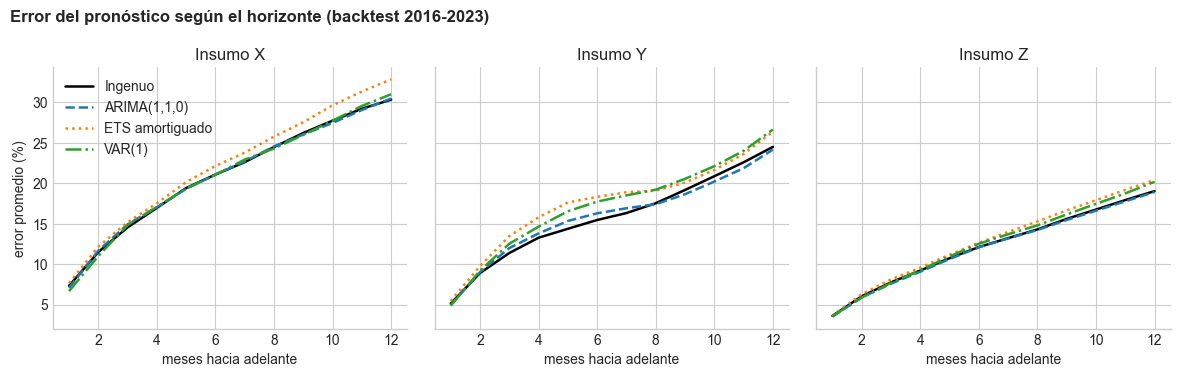

In [3]:
estilos = {"Ingenuo": ("black", "-"), "ARIMA(1,1,0)": ("#1f77b4", "--"),
           "ETS amortiguado": ("#ff7f0e", ":"), "VAR(1)": ("#2ca02c", "-.")}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, ins in zip(axes, ["X", "Y", "Z"]):
    for mod_, (col, ls) in estilos.items():
        ax.plot(mape.loc[ins].index, mape.loc[ins, mod_], color=col, linestyle=ls, label=mod_, linewidth=1.8)
    ax.set_title(f"Insumo {ins}")
    ax.set_xlabel("meses hacia adelante")
axes[0].set_ylabel("error promedio (%)")
axes[0].legend()
fig.suptitle("Error del pronóstico según el horizonte (backtest 2016-2023)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
guardar(fig, "03_backtest_modelos")

- Ningún modelo le gana al ingenuo. A 1 mes, ARIMA y VAR mejoran unas décimas y a partir de 3 meses las diferencias son mínimas o el ingenuo gana.
- El error crece con el tiempo, como en la mayoria de las caminatas aleatorias.
- Esto confirma que los precios de las materias primas no se pueden predecir mejor que el ingenuo usando solo su propia historia. Nuestro objetivo sera medir bien la incertidumbre y traducirla a presupuesto.

## 2. Error esperado de los equipos según el horizonte

Como los equipos son una mezcla de insumos, su error depende del modelo, el Equipo 2 diversifica (mezcla tres insumos), el Equipo 1 depende casi solo de Y.

In [4]:
horizontes = range(1, 13)
err_eq = pd.DataFrame({
    e: [100 * (mensual[e].shift(-k) / mensual[e] - 1).abs()["2016":].mean() for k in horizontes]
    for e in EQUIPOS}, index=pd.Index(horizontes, name="meses"))
err_eq.T

meses,1,2,3,4,5,6,7,8,9,10,11,12
Equipo1,5.2,9.3,12.0,14.1,15.4,17.1,18.5,20.2,22.5,24.9,27.2,29.3
Equipo2,3.6,6.3,8.2,9.6,11.1,12.7,14.3,15.9,17.7,19.6,21.3,23.0


El Equipo 2 es más predecible que el Equipo 1: la mezcla de tres insumos diversifica el riesgo (cuando uno sube, otro puede bajar).

## 3. Bandas de incertidumbre, simulación Monte Carlo

Se simulan 10,000 futuros posibles de X, Y y Z:

- Cada mes simulado toma un cambio mensual real de la historia (2010-2023), tomando los tres insumos del mismo mes juntos. Así se respeta su **correlación** (por ejemplo, en una crisis todos caen a la vez) y los meses extremos como COVID, sin suponer una distribución normal.
- Los cambios se toman en bloques de 3 meses para conservar la inercia de corto plazo.

In [5]:
calib = pr.calibrar_escala(mensual, "2016-01-31", h=12, escalas=np.arange(1.0, 1.81, 0.1))
calib.style.format({"cobertura_90": "{:.1%}", "cobertura_50": "{:.1%}", "error_mediana_%": "{:.1f}"})

,cobertura_90,cobertura_50,error_mediana_%
escala,,,
1.000000,78.1%,33.7%,17.2
1.100000,81.4%,38.3%,17.2
1.200000,84.2%,41.8%,17.3
1.300000,87.3%,44.7%,17.3
1.400000,89.9%,48.0%,17.3
1.500000,91.7%,51.7%,17.3
1.600000,92.4%,54.5%,17.3
1.700000,94.4%,57.7%,17.3
1.800000,95.8%,61.2%,17.4


Con los cambios históricos tal cual (escala 1.0), la banda del 90% solo contenía al real 78% de las veces:
el periodo 2016-2023 (COVID, guerra en Ucrania, alzas de 2021) fue más volátil que el promedio histórico.
Con escala 1.4 la cobertura llega a 90% y la banda del 50% a 48%, bandas calibradas.

In [6]:
ESCALA = 1.4
H = 12
fechas = pd.date_range(mensual.index[-1] + pd.offsets.MonthEnd(1), periods=H, freq="ME")
sims = pr.simular(mensual, H, n=10_000, escala=ESCALA)
eq_sims = pr.a_equipos(sims, modelo, modelo["residuo_std_mensual_%"])
bandas_eq = {e: pr.bandas(t, fechas) for e, t in eq_sims.items()}
bandas_ins = {c: pr.bandas(sims[:, :, j], fechas) for j, c in enumerate(["X", "Y", "Z"])}

## 4. Pronóstico de los equipos (sep-2023 a ago-2024)

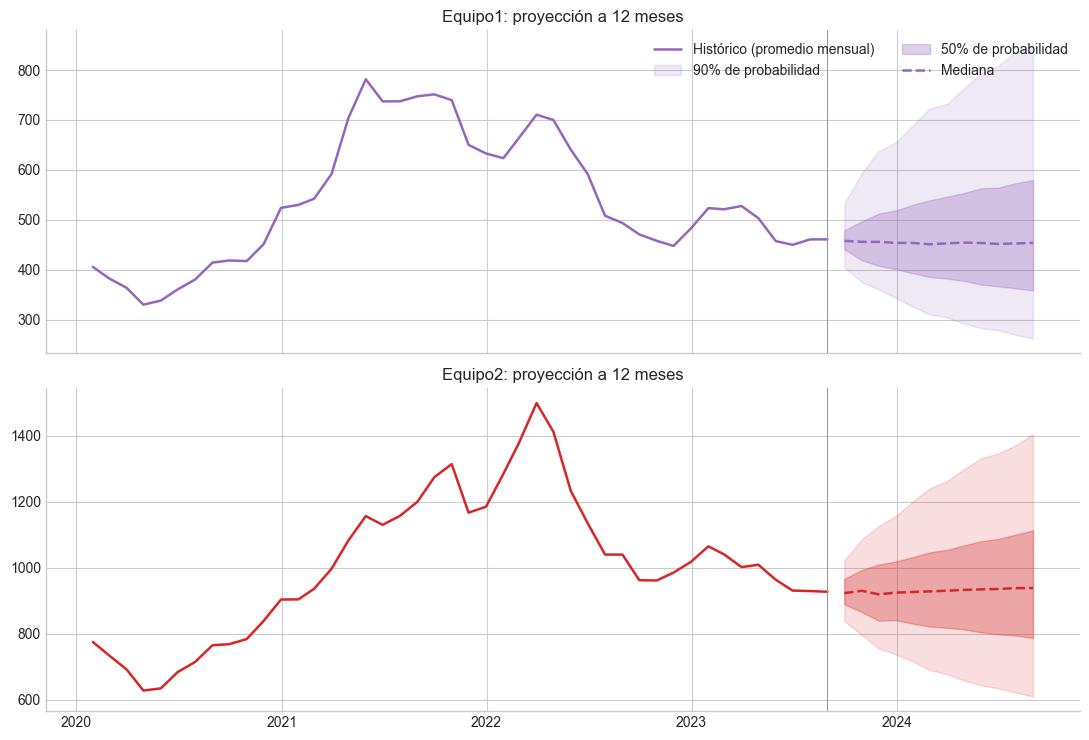

In [7]:
def abanico(ax, historia, b, color, titulo):
    ax.plot(historia.index, historia, color=color, linewidth=1.8, label="Histórico (promedio mensual)")
    ax.fill_between(b.index, b.P5, b.P95, color=color, alpha=0.15, label="90% de probabilidad")
    ax.fill_between(b.index, b.P25, b.P75, color=color, alpha=0.30, label="50% de probabilidad")
    ax.plot(b.index, b.P50, color=color, linestyle="--", linewidth=1.8, label="Mediana")
    ax.axvline(historia.index[-1], color="#999", linewidth=0.8)
    ax.set_title(titulo)

fig, axes = plt.subplots(2, 1, figsize=(11, 7.5), sharex=True)
for ax, e in zip(axes, EQUIPOS):
    abanico(ax, mensual[e]["2020":], bandas_eq[e], COLORES[e], f"{e}: proyección a 12 meses")
axes[0].legend(loc="upper right", ncol=2)
fig.tight_layout()
guardar(fig, "03_abanico_equipos")

In [8]:
for e in EQUIPOS:
    b = bandas_eq[e].copy()
    b["±90% (%)"] = 100 * (b.P95 - b.P5) / 2 / b.P50
    print(f"\n=== {e}  (último mes observado: {mensual[e].iloc[-1]:,.1f})")
    display(b[["P5", "P25", "P50", "P75", "P90", "P95", "±90% (%)"]])


=== Equipo1  (último mes observado: 461.0)


,P5,P25,P50,P75,P90,P95,±90% (%)
2023-09-30,404.8,441.5,458.1,479.2,513.3,533.1,14.0
2023-10-31,375.6,419.2,455.9,496.6,549.3,593.6,23.9
2023-11-30,360.9,408.0,456.0,512.4,601.3,637.7,30.4
2023-12-31,343.6,401.3,453.9,518.9,601.4,655.7,34.4
2024-01-31,325.7,392.9,453.8,530.5,623.5,690.5,40.2
2024-02-29,310.5,385.7,451.1,539.0,640.7,723.2,45.7
2024-03-31,304.7,382.4,453.0,546.4,653.8,732.2,47.2
2024-04-30,292.3,377.9,454.5,553.7,679.0,763.4,51.8
2024-05-31,283.1,370.5,453.7,563.2,695.7,793.9,56.3
2024-06-30,279.2,366.9,451.9,564.3,704.1,808.5,58.6



=== Equipo2  (último mes observado: 927.7)


,P5,P25,P50,P75,P90,P95,±90% (%)
2023-09-30,838.8,889.9,923.4,966.6,"1,003.6","1,022.7",10.0
2023-10-31,797.0,866.2,930.7,993.5,"1,051.7","1,086.1",15.5
2023-11-30,756.3,840.0,920.0,"1,010.0","1,089.3","1,126.8",20.1
2023-12-31,737.6,841.5,925.0,"1,019.6","1,110.4","1,157.8",22.7
2024-01-31,715.9,830.8,927.1,"1,033.1","1,136.2","1,202.8",26.3
2024-02-29,690.4,822.0,928.8,"1,047.0","1,166.6","1,241.2",29.6
2024-03-31,677.3,818.4,930.8,"1,054.7","1,186.0","1,263.6",31.5
2024-04-30,659.0,813.5,933.3,"1,068.3","1,209.2","1,299.3",34.3
2024-05-31,643.3,804.4,934.9,"1,081.0","1,232.8","1,332.4",36.9
2024-06-30,635.2,798.7,936.2,"1,087.8","1,242.4","1,347.1",38.0


## 5. Validación con datos reales que el modelo nunca vio

El archivo X.csv trae precios hasta abril de 2024, después del corte de la tabla de equipos (ago-2023).
Es una prueba real fuera de muestra, ahora revisamos si los precios reales de X cayeron dentro de la banda pronosticada.

In [9]:
x_real = datos.cargar_insumo("X").resample("ME").mean().reindex(fechas).dropna()
bx = bandas_ins["X"].loc[x_real.index].copy()
bx["real"] = x_real
bx["¿dentro del 90%?"] = (bx.real >= bx.P5) & (bx.real <= bx.P95)
bx["¿dentro del 50%?"] = (bx.real >= bx.P25) & (bx.real <= bx.P75)
bx[["P5", "P25", "P50", "P75", "P95", "real", "¿dentro del 90%?", "¿dentro del 50%?"]]

,P5,P25,P50,P75,P95,real,¿dentro del 90%?,¿dentro del 50%?
2023-09-30,67.6,79.7,86.3,91.5,100.4,92.6,True,False
2023-10-31,61.0,78.3,85.8,96.1,110.9,88.7,True,True
2023-11-30,54.6,76.5,85.5,99.1,118.6,82.0,True,True
2023-12-31,50.0,74.4,86.4,100.3,126.4,77.3,True,True
2024-01-31,45.6,72.2,86.7,102.9,134.7,79.1,True,True
2024-02-29,42.9,70.9,87.2,105.2,140.1,81.7,True,True
2024-03-31,41.2,69.4,86.9,107.5,145.7,84.5,True,True
2024-04-30,38.5,67.6,87.4,110.6,152.7,88.7,True,True


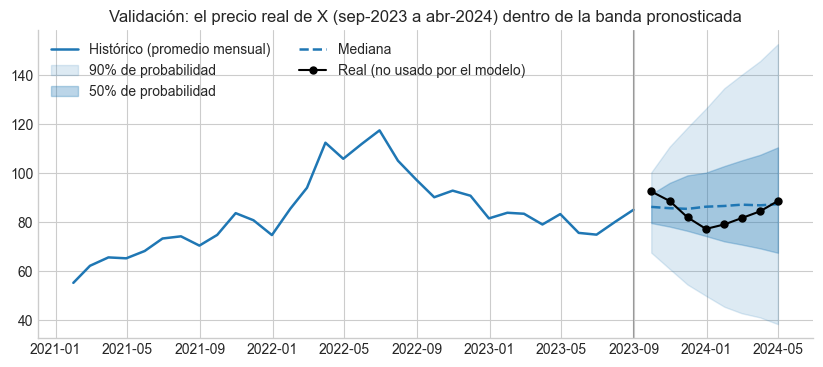

In [10]:
fig, ax = plt.subplots()
abanico(ax, mensual["X"]["2021":], bandas_ins["X"].loc[:x_real.index[-1]], COLORES["X"],
        "Validación: el precio real de X (sep-2023 a abr-2024) dentro de la banda pronosticada")
ax.plot(x_real.index, x_real, color="black", marker="o", markersize=5, linewidth=1.5, label="Real (no usado por el modelo)")
ax.legend(loc="upper left", ncol=2)
guardar(fig, "03_validacion_X")

Los 8 meses reales de X caen dentro de la banda del 90% y la mayoría dentro de la del 50%.

## 6. ¿Qué horizonte de predicción usar?

Depende de cuánto error es tolerable para presupuestar.
Si proyectamos mientras el error esperado sea menor a 15%, aun considero que sería un buen resultado.

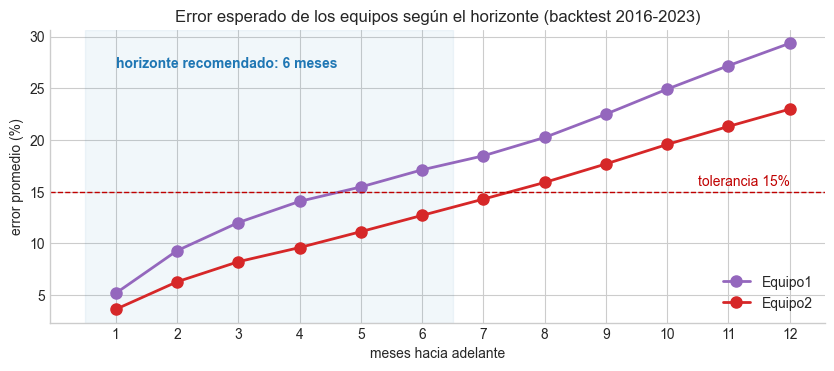

In [11]:
fig, ax = plt.subplots(figsize=(10, 3.8))
for e in EQUIPOS:
    ax.plot(err_eq.index, err_eq[e], color=COLORES[e], marker="o", markersize=8, label=e, linewidth=2)
ax.axhline(15, color="#c00000", linewidth=1, linestyle="--")
ax.text(12, 15.6, "tolerancia 15%", ha="right", color="#c00000")
ax.axvspan(0.5, 6.5, color="#1f77b4", alpha=0.06)
ax.text(1, 27, "horizonte recomendado: 6 meses", color="#1f77b4", fontweight="bold")
ax.set_xticks(range(1, 13))
ax.set_xlabel("meses hacia adelante")
ax.set_ylabel("error promedio (%)")
ax.set_title("Error esperado de los equipos según el horizonte (backtest 2016-2023)")
ax.legend(loc="lower right")
guardar(fig, "03_horizonte")

### Justificación del horizonte

- **Equipo 1** cruza el 15% de error alrededor del mes 5-6; **Equipo 2** alrededor del mes 7-8.
- Horizonte recomendado: **6** meses
- Pronosticar más lejos con un modelo más complejo no ayuda: el backtest mostró que la complejidad no reduce el error.

## 7. De pronóstico a presupuesto

Para el presupuesto no basta con la mediana. Propuesta:
- Presupuesto base = P50 (escenario central).
- Presupuesto con contingencia = P80 (80% de probabilidad de no excederlo).
- Reserva de contingencia = P80 - P50: pesos que absorbe la volatilidad.

In [12]:
tabla = []
for e in EQUIPOS:
    q = np.quantile(eq_sims[e][:, :6], [0.5, 0.8, 0.9], axis=0)
    for k in range(6):
        tabla.append({"mes": fechas[k].strftime("%b-%Y"), "equipo": e,
                      "P50 (base)": q[0, k], "P80 (con contingencia)": q[1, k],
                      "P90 (conservador)": q[2, k], "reserva P80-P50": q[1, k] - q[0, k],
                      "reserva %": 100 * (q[1, k] / q[0, k] - 1)})
presupuesto = pd.DataFrame(tabla).set_index(["equipo", "mes"])
presupuesto

P50 (base)  P80 (con contingencia)  P90 (conservador)  \
equipo  mes                                                               
Equipo1 Sep-2023       458.1                   488.3              513.3   
        Oct-2023       455.9                   510.4              549.3   
        Nov-2023       456.0                   528.8              601.3   
        Dec-2023       453.9                   539.3              601.4   
        Jan-2024       453.8                   552.3              623.5   
        Feb-2024       451.1                   566.8              640.7   
Equipo2 Sep-2023       923.4                   974.6            1,003.6   
        Oct-2023       930.7                 1,004.4            1,051.7   
        Nov-2023       920.0                 1,030.4            1,089.3   
        Dec-2023       925.0                 1,045.1            1,110.4   
        Jan-2024       927.1                 1,064.0            1,136.2   
        Feb-2024       928.8                 1,079.0            1,166.6   

                  reserva P80-P50  reserva %  
equipo  mes                                   
Equipo1 Sep-2023             30.2        6.6  
        Oct-2023             54.5       11.9  
        Nov-2023             72.8       16.0  
        Dec-2023             85.3       18.8  
        Jan-2024             98.5       21.7  
        Feb-2024            115.7       25.6  
Equipo2 Sep-2023             51.2        5.5  
        Oct-2023             73.7        7.9  
        Nov-2023            110.4       12.0  
        Dec-2023            120.1       13.0  
        Jan-2024            136.9       14.8  
        Feb-2024            150.2       16.2

Ejemplo de uso: si el proyecto compra N unidades del Equipo 1 en febrero de 2024, el presupuesto debería ser N × P80 de ese mes, y la diferencia contra N × P50 es la reserva por volatilidad.

## 8. Escenarios de crisis

Además de la simulación, se aplican momentos históricos reales a los precios actuales, el peor alza de 6 meses de cada insumo en la historia, y alzas hipotéticas de +20%.

In [13]:
ultimo = mensual[["X", "Y", "Z"]].iloc[-1]
alza6 = (mensual[["X", "Y", "Z"]].pct_change(6))
peor = alza6.max()
peor_fecha = alza6.idxmax()

escenarios = {
    "Actual (ago-2023)": {"X": 0, "Y": 0, "Z": 0},
    "Y +20%": {"X": 0, "Y": 0.20, "Z": 0},
    "Z +20%": {"X": 0, "Y": 0, "Z": 0.20},
    "X +20%": {"X": 0.20, "Y": 0, "Z": 0},
    f"Peor alza 6m de Y ({peor_fecha['Y']:%b-%Y}, +{100*peor['Y']:.0f}%)": {"X": 0, "Y": peor["Y"], "Z": 0},
    f"Peor alza 6m de Z ({peor_fecha['Z']:%b-%Y}, +{100*peor['Z']:.0f}%)": {"X": 0, "Y": 0, "Z": peor["Z"]},
    "Tormenta: X, Y y Z +20%": {"X": 0.20, "Y": 0.20, "Z": 0.20},
}
filas = {}
for nombre, ch in escenarios.items():
    precios = ultimo * (1 + pd.Series(ch))
    filas[nombre] = {e: float(precios @ modelo.loc[e, ["X", "Y", "Z"]]) for e in EQUIPOS}
esc = pd.DataFrame(filas).T
base = esc.iloc[0]
for e in EQUIPOS:
    esc[f"{e} cambio %"] = 100 * (esc[e] / base[e] - 1)
esc

,Equipo1,Equipo2,Equipo1 cambio %,Equipo2 cambio %
Actual (ago-2023),462.1,924.3,0.0,0.0
Y +20%,551.1,961.7,19.3,4.0
Z +20%,462.1,"1,066.2",0.0,15.3
X +20%,465.4,930.0,0.7,0.6
"Peor alza 6m de Y (May-2021, +74%)",790.0,"1,061.9",71.0,14.9
"Peor alza 6m de Z (Nov-2020, +32%)",462.1,"1,153.1",0.0,24.8
"Tormenta: X, Y y Z +20%",554.5,"1,109.2",20.0,20.0


- Un alza de 20% en "Y" sube el Equipo 1 casi 20% (depende casi solo de "Y"), pero el Equipo 2 solo 4%.
- Un alza de 20% en "X" apenas mueve a los dos equipos (0.6%): "X" es significativo pero pesa poco.
- Si se repitiera el peor episodio histórico de "Y", el Equipo 1 subiría en una proporción similar en 6 meses:
  ese es el **riesgo de cola** que conviene cubrir por contrato.

## 9. Guardar resultados (insumo para el agente de IA y el informe)

In [14]:
largo = []
for e, b in {**bandas_eq, **bandas_ins}.items():
    t = b.copy()
    t["serie"] = e
    t["mes"] = t.index.strftime("%Y-%m")
    largo.append(t.reset_index(drop=True))
pronostico = pd.concat(largo)[["serie", "mes", "P5", "P10", "P25", "P50", "P75", "P90", "P95"]]
pronostico.to_csv(datos.PROCESSED / "pronostico.csv", index=False)
presupuesto.to_csv(datos.PROCESSED / "presupuesto_6m.csv")
esc.to_csv(datos.PROCESSED / "escenarios.csv")
err_eq.to_csv(datos.PROCESSED / "error_por_horizonte.csv")
mape.to_csv(datos.PROCESSED / "backtest_modelos.csv")
pronostico.head()

,serie,mes,P5,P10,P25,P50,P75,P90,P95
0,Equipo1,2023-09,404.8,423.3,441.5,458.1,479.2,513.3,533.1
1,Equipo1,2023-10,375.6,388.1,419.2,455.9,496.6,549.3,593.6
2,Equipo1,2023-11,360.9,372.1,408.0,456.0,512.4,601.3,637.7
3,Equipo1,2023-12,343.6,362.4,401.3,453.9,518.9,601.4,655.7
4,Equipo1,2024-01,325.7,350.1,392.9,453.8,530.5,623.5,690.5
